# Importaciones necesarias


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

# Carga y exploración de datos
El primer paso será cargar los datos y realizar un análisis exploratorio de estos. 

In [ ]:
df = pd.read_csv('/workspace/Housing.csv')

print("--- Primeras 5 filas ---")
display(df.head())

print("\n--- Información del dataset ---")
df.info()

print("\n--- Valores nulos por columna ---")
print(df.isnull().sum())

print("\n--- Estadísticas descriptivas ---")
display(df.describe())

--- Primeras 5 filas ---


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



--- Información del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

--- Valores nulos por columna ---
price               0
area                0
bedrooms            0
bathrooms           

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


Tras este análisis inicial vamos a realizar unos gráficos descriptivos para visualizar la distribución de las variables. 

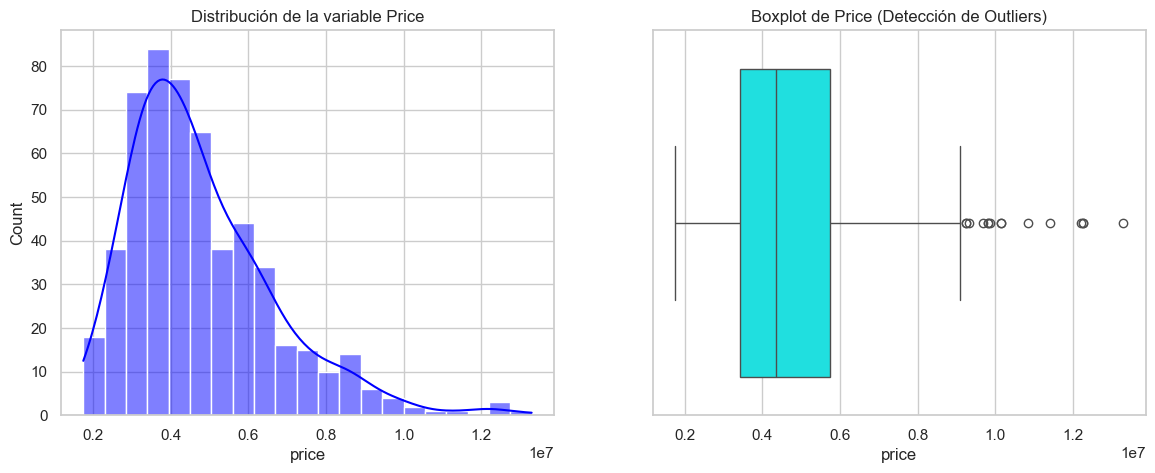

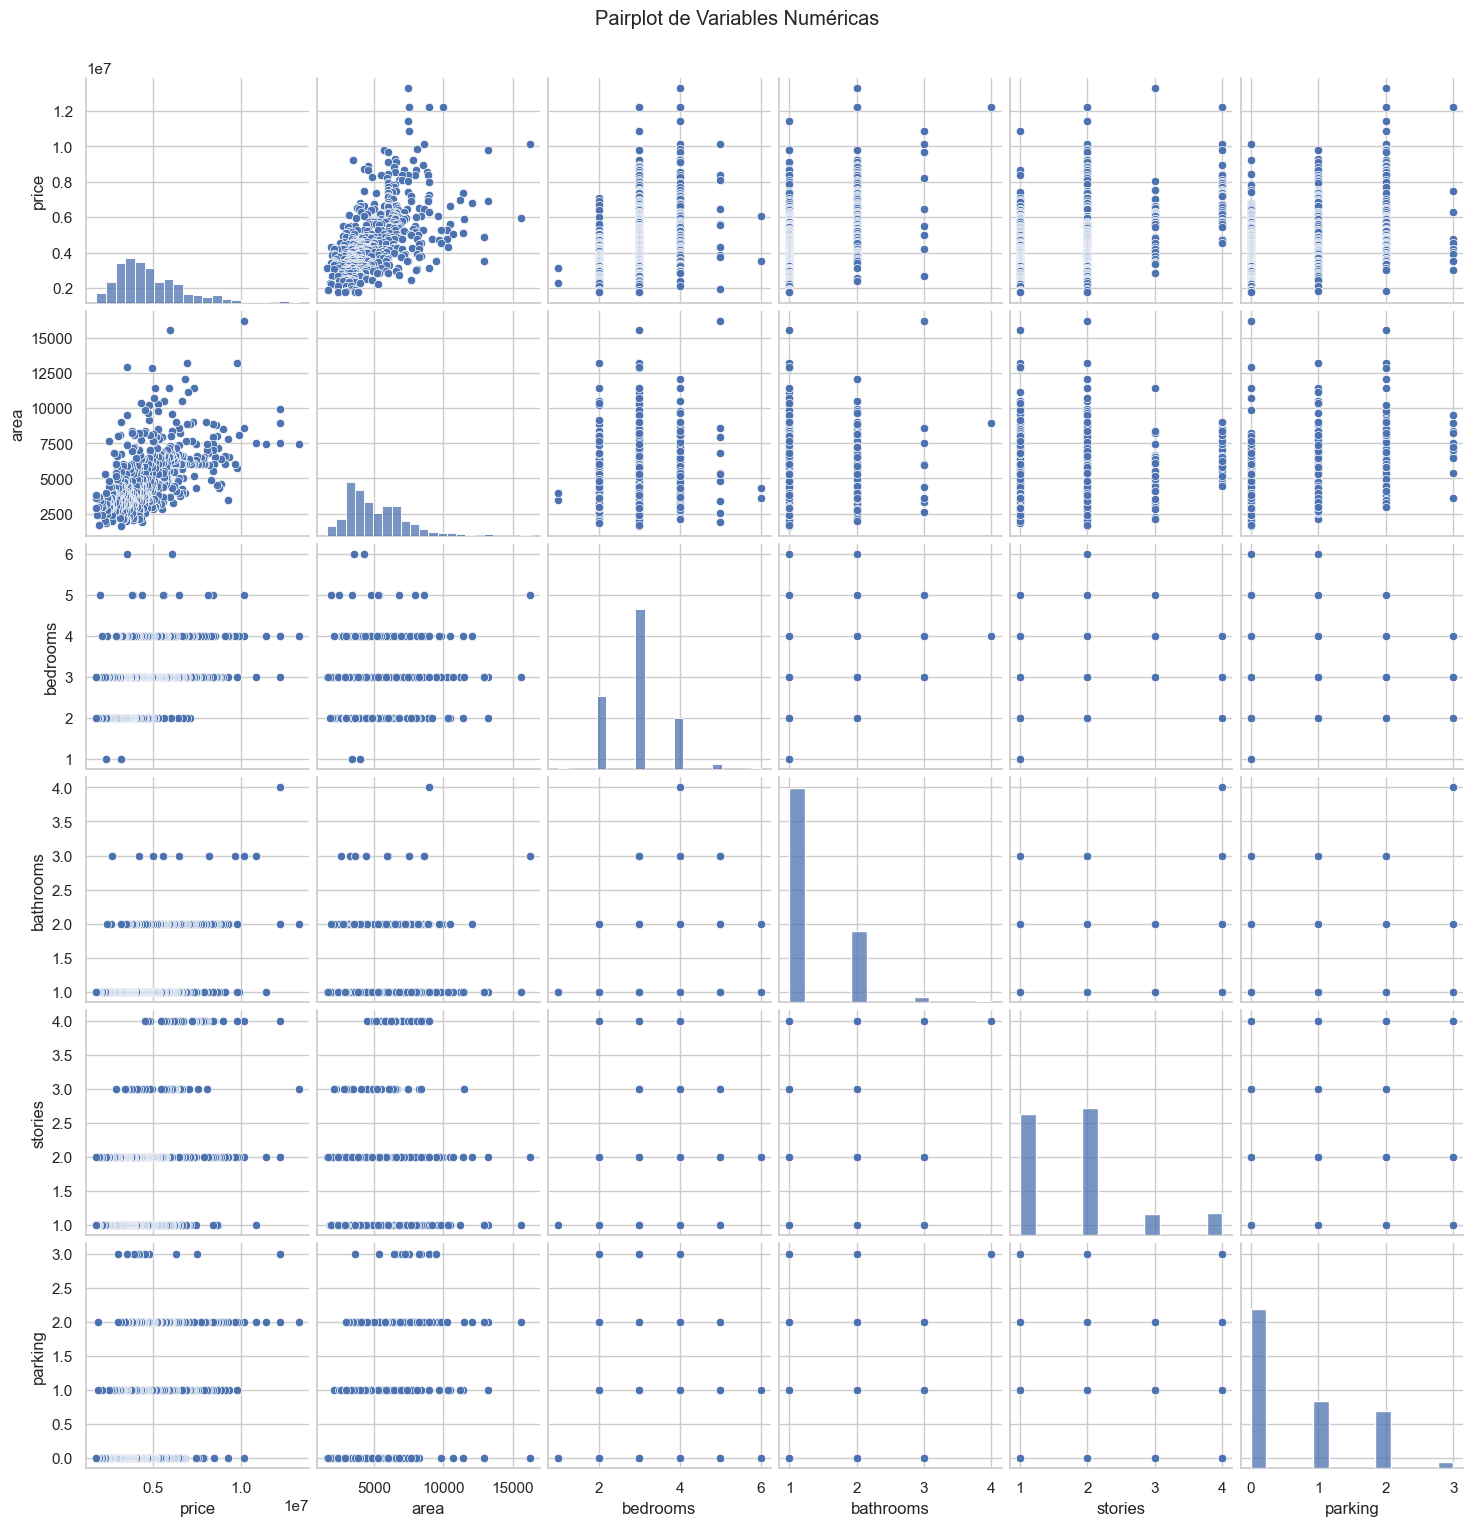

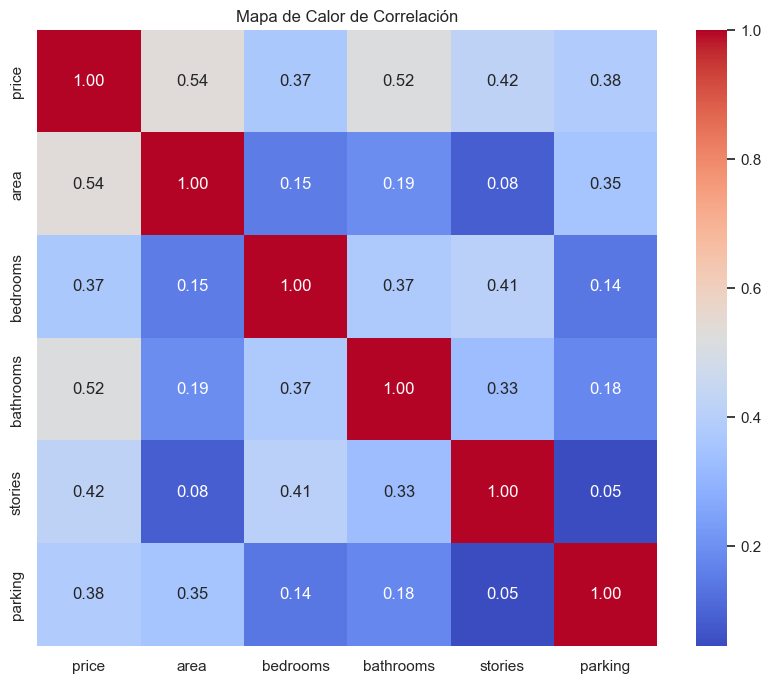

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de price
sns.histplot(df['price'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribución de la variable Price')

# Boxplot de price
sns.boxplot(x=df['price'], ax=axes[1], color='cyan')
axes[1].set_title('Boxplot de Price (Detección de Outliers)')
plt.show()

# Pairplot 
columnas_numericas = df.select_dtypes(include=['int64', 'float64']).columns
sns.pairplot(df[columnas_numericas])
plt.suptitle('Pairplot de Variables Numéricas', y=1.02)
plt.show()

# Mapa de calor de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(df[columnas_numericas].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Correlación')
plt.show()

# Preprocesamiento de datos

Como ya vimos en el análisis inicial no existen valores nulos, por lo tanto no es necesario hacer nada respecto a ello. En este paso entonces transformaremos las columnas categóricas. 

In [5]:
columnas_categoricas = df.select_dtypes(include=['object']).columns

df_procesado = pd.get_dummies(df, columns=columnas_categoricas, drop_first=True)

display(df_procesado.head())

,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,True,False,False,False,True,True,False,False
1,12250000,8960,4,4,4,3,True,False,False,False,True,False,False,False
2,12250000,9960,3,2,2,2,True,False,True,False,False,True,True,False
3,12215000,7500,4,2,2,3,True,False,True,False,True,True,False,False
4,11410000,7420,4,1,2,2,True,True,True,False,True,False,False,False


# División del dataset
Ahora dividremos los datos en conjuntos de entrenamiento y prueba. Aparte, estandarizamos para que todas las variables numéricas estén en la misma escala. 

In [7]:
X = df_procesado.drop('price', axis=1)
y = df_procesado['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Creación del modelo de regresión
Primero inicializamos y entrenamos el modelo. 

In [8]:
modelo_rl = LinearRegression()
modelo_rl.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Mostramos el intercepto y los coeficientes. 

In [9]:
print(f"Intercepto del modelo: {modelo_rl.intercept_:,.2f}\n")

coeficientes = pd.DataFrame(
    data=modelo_rl.coef_, 
    index=X.columns, 
    columns=['Coeficiente']
).sort_values(by='Coeficiente', ascending=False)

print("Coeficientes de las variables independientes:")
display(coeficientes)

Intercepto del modelo: 4,706,527.39

Coeficientes de las variables independientes:


,Coeficiente
bathrooms,521879.027748
area,519552.416340
airconditioning_yes,365157.393851
stories,349251.438906
prefarea_yes,266656.351993
parking,192005.953667
basement_yes,187067.803214
hotwaterheating_yes,149862.702991
mainroad_yes,128498.628215
guestroom_yes,88768.667686


# Evaluación del modelo
Tras entrenar el modelo vamos a evaluarlo. 

In [10]:
y_pred = modelo_rl.predict(X_test_scaled)

# Calcular métricas
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Error Cuadrático Medio (MSE): {mse:,.2f}")
print(f"Error Absoluto Medio (MAE): {mae:,.2f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")

Error Cuadrático Medio (MSE): 1,754,318,687,330.67
Error Absoluto Medio (MAE): 970,043.40
Coeficiente de Determinación (R²): 0.6529


# Visualización de resultados

Por último vamos a comparar los valores reales y predichos mediante una gráfica de dispersión. Así, coomo visualizaremos la distribución de los errores residuales para evaluar la precisión del modelo. 

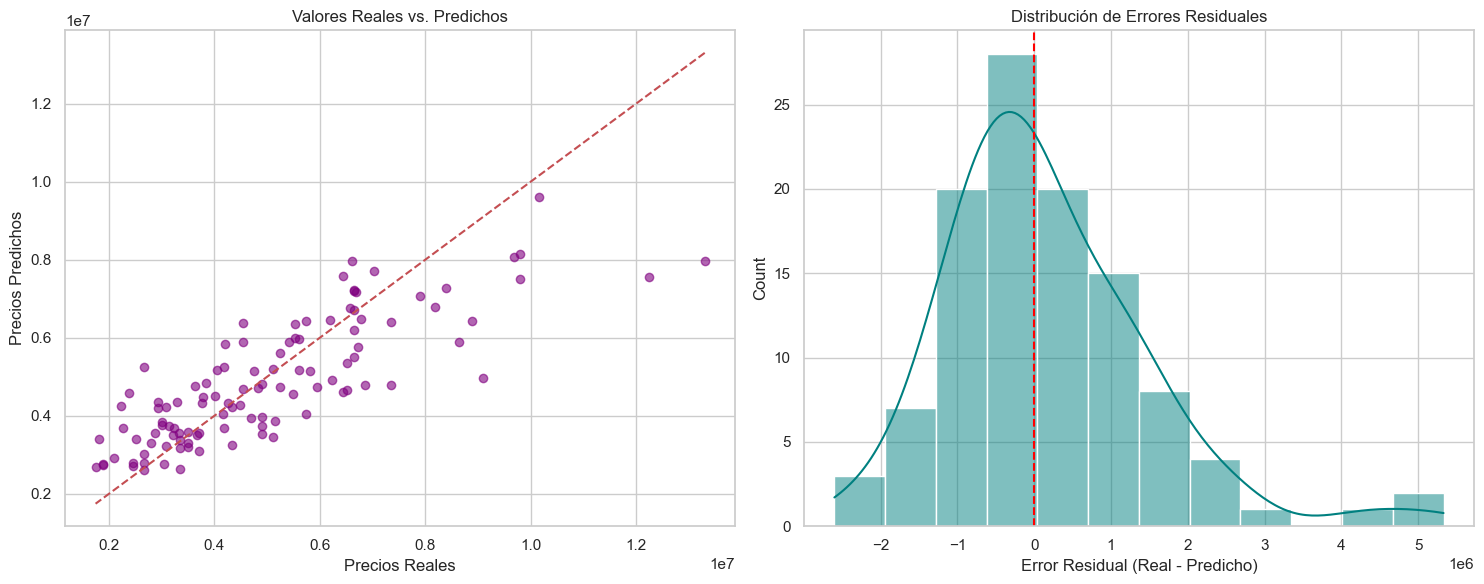

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(y_test, y_pred, alpha=0.6, color='purple')
p1 = max(max(y_test), max(y_pred))
p2 = min(min(y_test), min(y_pred))
axes[0].plot([p1, p2], [p1, p2], 'r--')
axes[0].set_xlabel('Precios Reales')
axes[0].set_ylabel('Precios Predichos')
axes[0].set_title('Valores Reales vs. Predichos')

residuos = y_test - y_pred
sns.histplot(residuos, kde=True, ax=axes[1], color='teal')
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_xlabel('Error Residual (Real - Predicho)')
axes[1].set_title('Distribución de Errores Residuales')

plt.tight_layout()
plt.show()